# 💊 Farmácias Boa Dose: Previsão de Demanda

Estudo de caso de **previsão de vendas (série temporal)** para uma rede fictícia de farmácias. O objetivo é ajudar o time de compras a decidir **quanto pedir de cada produto** nas próximas semanas, com menos falta de produto na prateleira e menos estoque parado.

**Sumário**

1. Entendimento do Negócio e Contextualização
2. Bibliotecas utilizadas
3. Carregamento dos dados
4. Descrição dos dados
5. Limpeza
6. Análise Exploratória
7. Modelagem
8. Conclusões e Recomendações
9. Deploy: como reproduzir

## 1. Entendimento do Negócio e Contextualização

### A empresa

A **Farmácias Boa Dose** é uma rede regional fundada em 2015 no Paraná. Hoje tem **5 lojas**: duas em Curitiba, uma em Londrina, uma em Maringá e uma em Ponta Grossa. O foco é o atendimento de bairro: medicamentos sem receita, higiene, beleza e cuidados com a saúde.

As compras são centralizadas. Um time pequeno faz o pedido para os fornecedores toda semana, e os produtos chegam no centro de distribuição de Curitiba antes de seguir para as lojas.

### O problema

Hoje o pedido é feito de um jeito bem simples: **"pede o mesmo tanto que vendeu na semana passada"**. Na maior parte do ano isso funciona, mas quebra justo nos momentos que mais importam:

- **No inverno**, a procura por antigripais e xaropes sobe rápido. Como o pedido segue a semana anterior, ele fica sempre atrasado, e as lojas ficam **sem produto na prateleira (ruptura)** no pico da gripe.
- **No fim do verão**, acontece o contrário: o protetor solar continua sendo pedido no ritmo de janeiro e sobra **estoque parado**, ocupando espaço e capital.
- **Promoções e feriados** mudam as vendas de um jeito que a regra atual não enxerga.

Em 2025 a diretoria percebeu que a regra estava custando caro dos dois lados: vendas perdidas por falta de produto e dinheiro preso em estoque. Por isso pediu um estudo usando o histórico de vendas.

### O objetivo

Entender como as vendas se comportam ao longo do tempo (tendência, sazonalidade, promoções e feriados) e construir uma **previsão semanal de vendas por produto** para as próximas **4 semanas** (janeiro de 2026). A previsão precisa errar **menos** que a regra atual.

### Os dados

Histórico de vendas diárias de **2023-01-01 a 2025-12-31** (3 anos), com cerca de **20 produtos** nas 5 lojas. Os dados vêm do sistema das lojas e têm problemas comuns de base real, que serão tratados na limpeza.

### Perguntas de negócio

1. Como as vendas da rede evoluíram de 2023 a 2025? Existe tendência de crescimento?
2. Quais produtos têm sazonalidade forte e em quais meses ficam no pico?
3. Quanto as promoções e os feriados mexem nas vendas?
4. As lojas se comportam de forma parecida ou alguma foge do padrão?
5. Dá para prever as vendas semanais das próximas 4 semanas errando menos que a regra atual ("repete a semana passada")?
6. Quanto pedir de cada produto nas próximas 4 semanas?

### Estrutura do projeto

Todos os arquivos ficam na raiz da pasta:

```
pharmacy-demand-forecast/
├── pharmacy_demand_forecast.ipynb   # notebook com a análise completa
├── generate_data.py                 # script que gera as bases fictícias
├── stores.csv                       # cadastro das lojas
├── products.csv                     # cadastro dos produtos
├── sales.csv                        # vendas diárias por loja e produto
├── holidays.csv                     # feriados do período
├── requirements.txt                 # bibliotecas do ambiente
├── README.md                        # resumo do projeto
└── .gitignore
```

## 2. Bibliotecas utilizadas

As bibliotecas entram aqui conforme forem usadas ao longo do projeto.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Carregamento dos dados

Os dados estão em 4 arquivos CSV, gerados pelo script `generate_data.py`:

| Arquivo | Conteúdo |
|---|---|
| `stores.csv` | Cadastro das 5 lojas |
| `products.csv` | Cadastro dos 20 produtos, com categoria e preço |
| `holidays.csv` | Feriados nacionais do período |
| `sales.csv` | Vendas diárias por loja e produto, de 2023 a 2025 |

In [2]:
stores = pd.read_csv('stores.csv')
products = pd.read_csv('products.csv')
holidays = pd.read_csv('holidays.csv')
sales = pd.read_csv('sales.csv')

print('stores:', stores.shape)
print('products:', products.shape)
print('holidays:', holidays.shape)
print('sales:', sales.shape)

stores: (5, 4)
products: (20, 4)
holidays: (39, 2)
sales: (108543, 6)


In [3]:
display(stores)
print('\n')
display(products.head())
print('\n')
display(holidays.head())
print('\n')
display(sales.head())

,store_id,store_name,city,opening_date
0,S01,Curitiba Centro,Curitiba,2015-03-10
1,S02,Curitiba Batel,Curitiba,2017-08-21
2,S03,Londrina,Londrina,2018-05-14
3,S04,Maringá,Maringá,2019-11-04
4,S05,Ponta Grossa,Ponta Grossa,2021-02-08


,product_id,product_name,category,unit_price
0,P01,Antigripal Comprimidos,Gripe e resfriado,18.9
1,P02,Xarope para Tosse,Gripe e resfriado,24.5
2,P03,Descongestionante Nasal,Gripe e resfriado,15.9
3,P04,Pastilha para Garganta,Gripe e resfriado,12.9
4,P05,Vitamina C Efervescente,Vitaminas,21.9


,date,holiday_name
0,2023-01-01,Confraternização Universal
1,2023-02-20,Carnaval
2,2023-02-21,Carnaval
3,2023-04-07,Sexta-feira Santa
4,2023-04-21,Tiradentes


,date,store_id,product_name,units_sold,unit_price,on_promotion
0,2023-01-01,S01,Antigripal Comprimidos,3,18.9,0
1,2023-01-01,S01,Xarope para Tosse,2,24.5,0
2,2023-01-01,S01,Descongestionante Nasal,3,15.9,0
3,2023-01-01,S01,Pastilha para Garganta,3,12.9,0
4,2023-01-01,S01,VITAMINA C EFERVESCENTE,2,21.9,0


## 4. Descrição dos dados

Antes de limpar qualquer coisa, vamos entender o tamanho, os tipos e os problemas das bases. O foco é a tabela `sales`, que é a base da previsão. As tabelas de cadastro (`stores`, `products` e `holidays`) são pequenas e servem de referência.

In [4]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 108543 entries, 0 to 108542
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          108543 non-null  str    
 1   store_id      108543 non-null  str    
 2   product_name  108543 non-null  str    
 3   units_sold    108543 non-null  int64  
 4   unit_price    108543 non-null  float64
 5   on_promotion  108543 non-null  int64  
dtypes: float64(1), int64(2), str(3)
memory usage: 5.0 MB


In [5]:
print('Nulos no sales:')
print(sales.isna().sum())
print()
print('Duplicados no sales:', sales.duplicated().sum())
print()
for name, table in [('stores', stores), ('products', products), ('holidays', holidays)]:
    print(name, '- nulos:', table.isna().sum().sum(), '| duplicados:', table.duplicated().sum())

Nulos no sales:
date            0
store_id        0
product_name    0
units_sold      0
unit_price      0
on_promotion    0
dtype: int64

Duplicados no sales: 217

stores - nulos: 0 | duplicados: 0
products - nulos: 0 | duplicados: 0
holidays - nulos: 0 | duplicados: 0


In [6]:
print(sales['units_sold'].describe().round(2))
print()
print('Linhas com venda negativa:', (sales['units_sold'] < 0).sum())

count    108543.00
mean          8.39
std           5.74
min          -3.00
25%           4.00
50%           7.00
75%          11.00
max          62.00
Name: units_sold, dtype: float64

Linhas com venda negativa: 326


In [7]:
print('Nomes de produto diferentes no sales:', sales['product_name'].nunique())
print('Produtos no cadastro:', products['product_name'].nunique())
print()
fps_50 = sales['product_name'].str.lower().str.contains('fps')
print(sales.loc[fps_50 & sales['product_name'].str.contains('50'), 'product_name'].value_counts().rename(index=repr))

Nomes de produto diferentes no sales: 93
Produtos no cadastro: 20

product_name
'Protetor Solar FPS 50'     4973
'Protetor  Solar FPS 50'     117
'protetor solar fps 50'      114
'PROTETOR SOLAR FPS 50'      104
'Protetor Solar FPS 50 '     104
Name: count, dtype: int64


In [8]:
print('Período:', sales['date'].min(), 'a', sales['date'].max())
print()
coverage = sales.drop_duplicates().groupby('store_id').agg(rows=('date', 'size'), days=('date', 'nunique'))
coverage['missing_rows'] = 1096 * 20 - coverage['rows']
coverage

Período: 2023-01-01 a 2025-12-31



,rows,days,missing_rows
store_id,,,
S01,21703,1096,217
S02,21694,1096,226
S03,21709,1096,211
S04,21512,1087,408
S05,21708,1096,212


### Resumo dos problemas e decisões

| # | Problema | Quantidade | Decisão |
|---|---|---|---|
| 1 | Coluna `date` está como texto | 1 coluna | Converter para data com `pd.to_datetime` |
| 2 | Linhas duplicadas | 217 linhas | Remover |
| 3 | Nomes de produto escritos de vários jeitos (maiúsculas, minúsculas, espaços sobrando) | 93 nomes para 20 produtos | Padronizar o texto e trocar o nome pelo `product_id` do cadastro |
| 4 | Vendas negativas (devoluções lançadas como venda) | 326 linhas | Devolução não é procura. Tratar como valor faltando e preencher junto com o item 5 |
| 5 | Linhas faltando, incluindo 9 dias sem registro na loja de Maringá (S04) | 1.274 linhas | Montar a grade completa (todo dia × loja × produto) e preencher as vendas que faltam |

Sem nulos nas colunas e sem problemas nas tabelas de cadastro.

**Por que não preencher com zero?** Venda faltando não quer dizer que ninguém comprou, e sim que a venda não foi registrada. Se a gente colocar zero, a previsão aprende que em agosto de 2024 Maringá quase não vendeu, o que não é verdade.

## 5. Limpeza

Vamos tratar os problemas encontrados na seção 4, na ordem da tabela-resumo. O resultado é a tabela `sales_clean`, com **uma linha por dia, loja e produto** (1.096 dias × 5 lojas × 20 produtos = 109.600 linhas), que será usada na análise e na previsão.

In [9]:
sales['date'] = pd.to_datetime(sales['date'])
holidays['date'] = pd.to_datetime(holidays['date'])

print(sales['date'].dtype, holidays['date'].dtype)

datetime64[us] datetime64[us]


In [10]:
before = len(sales)
sales = sales.drop_duplicates()

print('Linhas removidas:', before - len(sales))
print('Linhas agora:', len(sales))

Linhas removidas: 217
Linhas agora: 108326


In [11]:
sales['product_name'] = sales['product_name'].str.strip().str.lower().str.split().str.join(' ')
print('Nomes diferentes agora:', sales['product_name'].nunique())

name_to_id = dict(zip(products['product_name'].str.lower(), products['product_id']))
sales['product_id'] = sales['product_name'].map(name_to_id)
print('Linhas sem product_id:', sales['product_id'].isna().sum())

Nomes diferentes agora: 20
Linhas sem product_id: 0


In [12]:
sales['units_sold'] = sales['units_sold'].mask(sales['units_sold'] < 0)

print('Vendas negativas que viraram vazio:', sales['units_sold'].isna().sum())

Vendas negativas que viraram vazio: 325


In [13]:
grid = pd.MultiIndex.from_product(
    [pd.date_range('2023-01-01', '2025-12-31'), stores['store_id'], products['product_id']],
    names=['date', 'store_id', 'product_id'],
).to_frame(index=False)

sales_clean = grid.merge(
    sales[['date', 'store_id', 'product_id', 'units_sold', 'on_promotion']],
    on=['date', 'store_id', 'product_id'],
    how='left',
)

print('Linhas da grade:', len(sales_clean))
print(sales_clean.isna().sum())

Linhas da grade: 109600
date               0
store_id           0
product_id         0
units_sold      1599
on_promotion    1274
dtype: int64


In [14]:
sales_clean = sales_clean.sort_values(['store_id', 'product_id', 'date'])

sales_clean['units_sold'] = (
    sales_clean.groupby(['store_id', 'product_id'])['units_sold']
    .transform(lambda s: s.interpolate(limit_direction='both'))
    .round()
    .astype(int)
)

sales_clean['on_promotion'] = (
    sales_clean.groupby(['date', 'product_id'])['on_promotion']
    .transform('max')
    .fillna(0)
    .astype(int)
)

print(sales_clean.isna().sum())

date            0
store_id        0
product_id      0
units_sold      0
on_promotion    0
dtype: int64


In [15]:
sales_clean = sales_clean.reset_index(drop=True)

sales_clean.info()
print()
print(sales_clean['units_sold'].describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          109600 non-null  datetime64[us]
 1   store_id      109600 non-null  str           
 2   product_id    109600 non-null  str           
 3   units_sold    109600 non-null  int64         
 4   on_promotion  109600 non-null  int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 4.2 MB

count    109600.00
mean          8.42
std           5.71
min           0.00
25%           4.00
50%           7.00
75%          11.00
max          62.00
Name: units_sold, dtype: float64


### Resumo da limpeza

| # | Problema | O que foi feito | Resultado |
|---|---|---|---|
| 1 | Data como texto | Convertida com `pd.to_datetime` | `date` virou data |
| 2 | Duplicados | Removidos com `drop_duplicates` | 217 linhas a menos |
| 3 | Nomes de produto bagunçados | Texto padronizado (sem espaços sobrando, tudo minúsculo) e trocado pelo `product_id` | De 93 para 20 nomes, todos encontrados no cadastro |
| 4 | Vendas negativas | Viraram valor vazio | 325 linhas |
| 5 | Linhas faltando | Grade completa de dia × loja × produto. Vendas preenchidas por **interpolação** (uma "ponte" entre o dia anterior e o seguinte da mesma loja e produto). Promoção copiada das outras lojas, porque as campanhas valem para a rede toda | 109.600 linhas, sem vazios |

A coluna `unit_price` ficou de fora: o preço só muda na promoção, e essa informação já está em `on_promotion`. A previsão é feita em **unidades**.

## 6. Análise Exploratória

Vamos responder às perguntas de negócio de 1 a 4, uma por vez. As perguntas 5 e 6 ficam para a Modelagem.

### 6.1 Como as vendas da rede evoluíram de 2023 a 2025?

In [18]:
yearly = sales_clean.groupby(sales_clean['date'].dt.year)['units_sold'].sum().to_frame()
yearly['growth_pct'] = (yearly['units_sold'].pct_change() * 100).round(1)

yearly

,units_sold,growth_pct
date,,
2023,296175,NaN
2024,310302,4.8
2025,316196,1.9


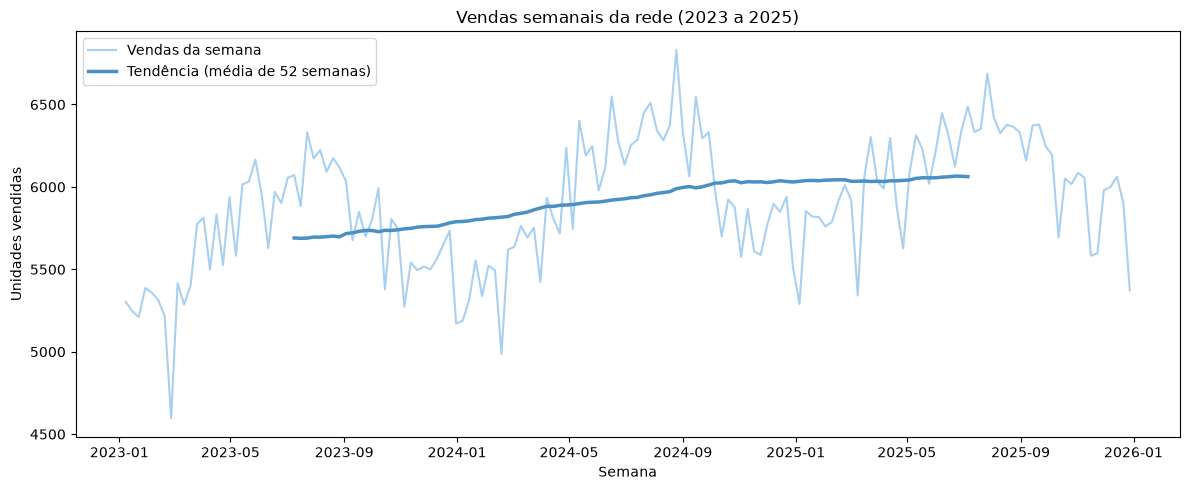

In [19]:
weekly = sales_clean.set_index('date')['units_sold'].resample('W').sum().iloc[1:-1].to_frame()
weekly['trend'] = weekly['units_sold'].rolling(52, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=weekly, x=weekly.index, y='units_sold', color='#a8d0f0', label='Vendas da semana', ax=ax)
sns.lineplot(data=weekly, x=weekly.index, y='trend', color='#4a90c2', linewidth=2.5, label='Tendência (média de 52 semanas)', ax=ax)
ax.set_title('Vendas semanais da rede (2023 a 2025)')
ax.set_xlabel('Semana')
ax.set_ylabel('Unidades vendidas')
plt.tight_layout()
plt.show()

#### Observações

**Fatos**

- A rede vendeu **296 mil unidades em 2023**, **310 mil em 2024 (+4,8%)** e **316 mil em 2025 (+1,9%)**.
- A linha de tendência sobe o tempo todo, de cerca de **5.700 para 6.060 unidades por semana**, mas fica quase reta a partir de 2025.
- Toda metade de ano tem uma "onda" de vendas mais altas, com o pico em julho e agosto. O começo do ano é o período mais fraco.
- Algumas semanas caem de repente, como a do Carnaval de 2023 (cerca de 4.600 unidades, a menor do período).

**Hipóteses (para checar nas próximas perguntas)**

- A onda do meio do ano deve vir dos produtos de gripe e resfriado (pergunta 2).
- As quedas de uma semana só devem ser os feriados (pergunta 3).
- O crescimento menor em 2025 pode vir de alguma loja específica (pergunta 4).

**O que isso significa para o negócio**

A procura cresce, mas a sazonalidade mexe muito mais com as vendas do que o crescimento de um ano para outro. Entre a semana mais fraca e a mais forte, a diferença passa de 2 mil unidades. Uma regra que só repete a semana passada vai sempre chegar atrasada nessas viradas.

### 6.2 Quais produtos têm sazonalidade forte e em quais meses ficam no pico?

Para comparar produtos que vendem quantidades bem diferentes, usamos o **índice sazonal**: a venda média de cada mês dividida pela média do próprio produto. O valor 1,0 é um mês normal, 1,5 é um mês 50% acima da média e 0,5 é um mês com metade da venda média.

In [20]:
season = sales_clean.merge(products[['product_id', 'product_name']], on='product_id')
season['month'] = season['date'].dt.month

monthly = season.groupby(['product_name', 'month'])['units_sold'].mean().unstack()
seasonal_index = monthly.div(monthly.mean(axis=1), axis=0).round(2)

summary = pd.DataFrame({
    'peak_month': seasonal_index.idxmax(axis=1),
    'low_month': seasonal_index.idxmin(axis=1),
    'peak_vs_low': (seasonal_index.max(axis=1) / seasonal_index.min(axis=1)).round(1),
}).sort_values('peak_vs_low', ascending=False)

summary

,peak_month,low_month,peak_vs_low
product_name,,,
Loção Pós-Sol,1,7,4.2
Protetor Solar FPS 30,12,7,3.9
Protetor Solar FPS 50,1,7,3.8
Antigripal Comprimidos,7,1,3.2
Xarope para Tosse,7,1,3.2
Pastilha para Garganta,7,1,3.1
Descongestionante Nasal,8,1,3.1
Soro de Reidratação,2,7,2.0
Repelente de Insetos,2,8,1.9


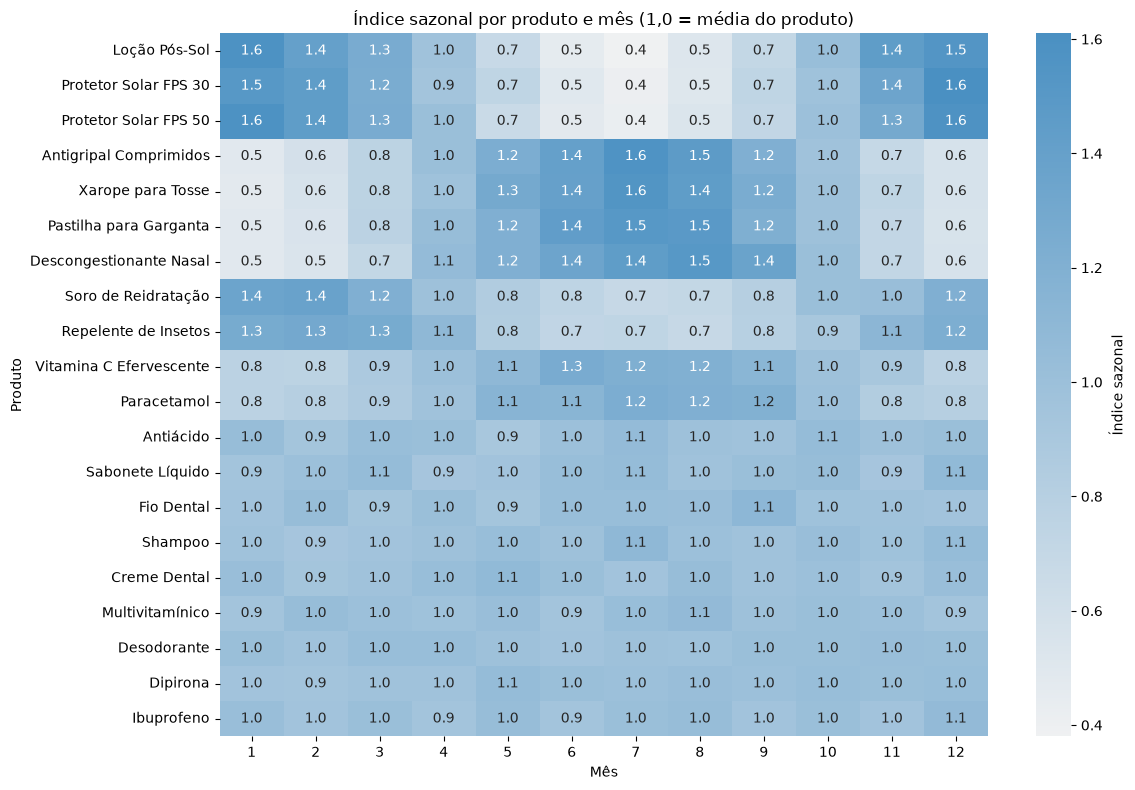

In [21]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    seasonal_index.loc[summary.index],
    cmap=sns.light_palette('#4a90c2', as_cmap=True),
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'Índice sazonal'},
    ax=ax,
)
ax.set_title('Índice sazonal por produto e mês (1,0 = média do produto)')
ax.set_xlabel('Mês')
ax.set_ylabel('Produto')
plt.tight_layout()
plt.show()

#### Observações

**Fatos**

Os produtos se dividem em 3 grupos bem claros:

| Grupo | Produtos | Pico | Mês mais fraco | Pico ÷ mês mais fraco |
|---|---|---|---|---|
| **Verão** | Loção Pós-Sol, Protetor Solar FPS 30 e FPS 50 | Dezembro e janeiro | Julho | 3,8 a 4,2 vezes |
| **Verão (mais fraco)** | Soro de Reidratação, Repelente de Insetos | Fevereiro | Julho e agosto | 1,9 a 2,0 vezes |
| **Inverno** | Antigripal, Xarope, Pastilha, Descongestionante | Julho e agosto | Janeiro | 3,1 a 3,2 vezes |
| **Inverno (mais fraco)** | Vitamina C, Paracetamol | Junho e julho | Janeiro e fevereiro | 1,6 a 1,7 vezes |
| **Estáveis** | Higiene, Dipirona, Ibuprofeno, Antiácido, Multivitamínico | Sem pico | Sem pico | 1,1 a 1,2 vezes |

- O protetor solar FPS 50 vende **1,6 vez a média em janeiro** e só **0,4 em julho**. O antigripal faz o caminho contrário: **1,6 em julho** e **0,5 em janeiro**.
- Nos produtos estáveis, o "mês de pico" da tabela muda de produto para produto. Com uma diferença de só 10% a 20%, isso é variação normal, não sazonalidade.

**Hipóteses**

- A onda de vendas do meio do ano vista na pergunta 1 vem do grupo de inverno: são 4 produtos que chegam a triplicar, contra 3 de verão que vendem menos unidades por dia.

**O que isso significa para o negócio**

- **9 dos 20 produtos** têm sazonalidade que muda o tamanho do pedido de verdade. São eles que sofrem com a regra "repete a semana passada": na subida, a regra pede de menos (ruptura); na descida, pede demais (estoque parado).
- Para as 4 semanas de janeiro de 2026, o protetor solar e o pós-sol estão **no topo** do ano, e os produtos de gripe estão **no fundo**. A previsão precisa levar isso em conta.
- Os 11 produtos estáveis podem seguir com reposição simples, baseada na média.